# Kan nyckeltal slå marknaden?

**Problem:** Kan ett bolags finansiella nyckeltal förutsäga om aktien får högre
avkastning än medianaktien det kommande året?

**Användare:** Privata investerare som vill ha en första sållning av vilka aktier
som är värda att analysera vidare.

**Upplägg:**

| Steg | År |
|---|---|
| Träning | 2014–2016 |
| Validering (modellval) | 2017 |
| Slutligt test | 2018 |

Målvariabeln är 1 om aktiens avkastning året efter är högre än medianen samma år,
annars 0. Varje år delas alltså 50/50, och slumpen ger cirka 50 % rätt.

**Om teståret:** 2018 kördes en gång i ett tidigt individuellt experiment.
Modellvalet i denna notebook gjordes enbart på 2017, enligt en regel som
bestämdes innan resultaten var kända.

Underlag: gemensam EDA i `eda_gemensam.ipynb`, experiment i `experiments.ipynb`,
individuella experiment i `old/`.

In [8]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_auc_score

from src.data_prep import load_year, build_dataset, FEATURES
from src.evaluation import evaluate, bootstrap_auc
from src.models import make_model

FEATURES_FINAL = FEATURES + ["has_loss"]
COLUMNS = FEATURES_FINAL + ["Sector"]

train = build_dataset([2014, 2015, 2016])
val = build_dataset([2017])
test = build_dataset([2018])

print("Träning:   ", train.shape)
print("Validering:", val.shape)
print("Test:      ", test.shape)

Träning:    (11549, 21)
Validering: (4127, 21)
Test:       (4141, 21)


## 1. Data

Källa: Kaggle, *200+ Financial Indicators of US Stocks (2014–2018)*. En fil per år
med cirka 4 000 amerikanska bolag och 225 kolumner.

Rensning (`src/data_prep.py`):
- Bolag som saknar mer än hälften av våra 14 nyckeltal tas bort.
- Avkastningar under −100 % (omöjliga) tas bort.
- P/E = 0 betyder förlust och görs om till saknat värde. Kolumnen `has_loss` läggs till.
- Börsvärdet logaritmeras eftersom det varierar enormt.
- Saknade värden fylls i med medianen från träningsdatan, inne i modellens pipeline.

In [9]:
rows = []
for year in [2014, 2015, 2016, 2017, 2018]:
    raw = load_year(year)
    clean = build_dataset([year])
    rows.append({
        "År": year,
        "Bolag före rensning": len(raw),
        "Bolag efter rensning": len(clean),
        "Borttagna (%)": round(100 * (1 - len(clean) / len(raw)), 1),
        "Medianavkastning nästa år (%)": round(clean["next_year_return"].median(), 1),
    })
pd.DataFrame(rows)

,År,Bolag före rensning,Bolag efter rensning,Borttagna (%),Medianavkastning nästa år (%)
0,2014,3808,3640,4.4,-5.4
1,2015,4120,3842,6.7,18.0
2,2016,4797,4067,15.2,11.5
3,2017,4960,4127,16.8,-16.3
4,2018,4392,4141,5.7,17.8


Mellan 4 och 17 % av bolagen tas bort varje år. 2016 och 2017 har mest
ofullständig data. Medianavkastningen varierar kraftigt, från −16 % till +18 %.
Det visar varför målvariabeln jämför aktier mot medianen samma år i stället för
att mäta om de steg eller föll.

## 2. Metod och modellval

**Baseline:** slumpmässig gissning och en enkel nyckeltalsregel (lägst P/B rankas högst).

**Modeller:** logistisk regression (enkel) och gradient boosting (avancerad).

**Mått:** ROC-AUC är huvudmåttet, eftersom det mäter hur väl modellen rangordnar
aktier. Vi redovisar även accuracy och medianavkastningen för de 10 % högst
respektive lägst rankade aktierna. Osäkerheten anges med 95 %-intervall från
bootstrap.

**Experiment på 2017** (detaljer i `experiments.ipynb`). Vi ändrade en sak i taget:

| Experiment | Logistisk regression | Random forest | Gradient boosting |
|---|---|---|---|
| Grund (15 nyckeltal) | 0,610 | 0,618 | 0,616 |
| + winsorisering | 0,621 | 0,622 | 0,617 |
| 5 nyckeltal i stället för 15 | 0,606 | 0,600 | 0,596 |
| + sektor | 0,626 | 0,632 | 0,633 |

Fler nyckeltal, winsorisering och sektor förbättrade resultaten. Skillnaderna
mellan modellerna var mindre än skillnaderna mellan förbehandlingarna.

Vi väljer den enklaste modellen om
skillnaden mot den bästa ligger inom osäkerheten. Båda modellerna testas på 2018.

**Slutlig uppsättning:** 15 nyckeltal, winsorisering och sektor.

In [10]:
lr_model = make_model("Logistisk regression", FEATURES_FINAL, winsor=True, sector=True)
gb_model = make_model("Gradient boosting", FEATURES_FINAL, winsor=True, sector=True)

lr_model.fit(train[COLUMNS], train["above_median"])
gb_model.fit(train[COLUMNS], train["above_median"])

def predictions(df):
    """Sannolikheter från baseline och båda modellerna för ett år."""
    rng = np.random.default_rng(42)
    return {
        "Slump": rng.random(len(df)),
        "Lågt P/B": df["PB ratio"].rank(ascending=False, pct=True).fillna(0.5).to_numpy(),
        "Logistisk regression": lr_model.predict_proba(df[COLUMNS])[:, 1],
        "Gradient boosting": gb_model.predict_proba(df[COLUMNS])[:, 1],
    }

def result_table(df, proba_dict):
    rows = []
    for name, proba in proba_dict.items():
        result = evaluate(df, proba, name)
        low, high = bootstrap_auc(df, proba)
        result["AUC 95 %-intervall"] = f"[{low:.3f}, {high:.3f}]"
        rows.append(result)
    return pd.DataFrame(rows)

val_proba = predictions(val)
val_results = result_table(val, val_proba)
val_results

,Accuracy,ROC-AUC,Topp 10 % (median avk.),Botten 10 % (median avk.),Alla (median avk.),AUC 95 %-intervall
Slump,0.499,0.488,-16.563,-13.254,-16.319,"[0.470, 0.506]"
Lågt P/B,0.476,0.484,-19.926,-11.082,-16.319,"[0.466, 0.502]"
Logistisk regression,0.596,0.626,-13.456,-39.285,-16.319,"[0.610, 0.643]"
Gradient boosting,0.596,0.633,-8.879,-40.250,-16.319,"[0.616, 0.650]"


In [11]:
def bootstrap_auc_diff(df, proba_a, proba_b, n_boot=1000, seed=42):
    """Skillnad i ROC-AUC (a minus b) på samma bootstrap-urval."""
    rng = np.random.default_rng(seed)
    y = df["above_median"].to_numpy()
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        diffs.append(roc_auc_score(y[idx], proba_a[idx]) - roc_auc_score(y[idx], proba_b[idx]))
    diffs = np.array(diffs)
    low, high = np.percentile(diffs, [2.5, 97.5])
    return pd.Series({
        "Skillnad i ROC-AUC": round(diffs.mean(), 3),
        "95 %-intervall": f"[{low:.3f}, {high:.3f}]",
        "Andel urval där GB är bättre": round((diffs > 0).mean(), 2),
    })

bootstrap_auc_diff(val, val_proba["Gradient boosting"], val_proba["Logistisk regression"])

Skillnad i ROC-AUC                        0.007
95 %-intervall                  [-0.005, 0.018]
Andel urval där GB är bättre               0.86
dtype: object

**Modellval:** Gradient boosting är 0,007 bättre, men intervallet för skillnaden
innehåller noll. Vi **logistisk regression**. Den är
enklare och lättare att tolka för användaren.

## 3. Slutligt test på 2018

Modellerna tränas inte om och inga inställningar ändras. Testet körs en gång.

In [12]:
test_proba = predictions(test)
test_results = result_table(test, test_proba)
test_results

,Accuracy,ROC-AUC,Topp 10 % (median avk.),Botten 10 % (median avk.),Alla (median avk.),AUC 95 %-intervall
Slump,0.504,0.507,15.723,15.464,17.773,"[0.489, 0.524]"
Lågt P/B,0.449,0.438,1.788,26.512,17.773,"[0.420, 0.456]"
Logistisk regression,0.596,0.630,22.677,-15.316,17.773,"[0.614, 0.648]"
Gradient boosting,0.607,0.636,22.040,-9.791,17.773,"[0.619, 0.654]"


In [13]:
pd.DataFrame({
    "ROC-AUC 2017": val_results.set_index(val_results.index)["ROC-AUC"],
    "ROC-AUC 2018": test_results["ROC-AUC"],
    "Accuracy 2017": val_results["Accuracy"],
    "Accuracy 2018": test_results["Accuracy"],
})

bootstrap_auc_diff(test, test_proba["Gradient boosting"], test_proba["Logistisk regression"])

Skillnad i ROC-AUC                        0.006
95 %-intervall                  [-0.005, 0.017]
Andel urval där GB är bättre               0.85
dtype: object

**Resultat:** Den valda modellen håller på teståret. ROC-AUC blev 0,630
(mot 0,626 på 2017) och accuracy 59,6 % båda åren, över vårt riktvärde på 55 %.

Gradient boosting var återigen marginellt bättre (+0,006), men skillnaden var
inte heller nu statistiskt säker. Att den var bättre båda åren tyder dock på en
liten verklig fördel som vår data inte räcker för att bekräfta.

P/B-regeln var sämre än slumpen båda åren. Att bara köpa billiga aktier hade
inte fungerat under perioden.

In [14]:
proba = test_proba["Logistisk regression"]
y_pred = (proba >= 0.5).astype(int)

pd.DataFrame(
    confusion_matrix(test["above_median"], y_pred),
    index=["Faktiskt: under median", "Faktiskt: över median"],
    columns=["Gissat: under", "Gissat: över"],
)

,Gissat: under,Gissat: över
Faktiskt: under median,1167,904
Faktiskt: över median,767,1303


Av de 2 207 aktier modellen trodde skulle slå medianen gjorde 1 303 det (59 %).
Felen är ungefär jämnt fördelade mellan klasserna.

In [15]:
(test.assign(correct=(y_pred == test["above_median"]))
    .groupby("Sector")
    .agg(Bolag=("correct", "size"), Andel_rätt=("correct", "mean"))
    .sort_values("Andel_rätt")
    .round(3))

,Bolag,Andel_rätt
Sector,,
Communication Services,78,0.551
Consumer Cyclical,487,0.559
Basic Materials,271,0.565
Financial Services,672,0.568
Consumer Defensive,183,0.590
Healthcare,688,0.599
Real Estate,239,0.603
Industrials,560,0.607
Technology,628,0.610


Träffsäkerheten varierar från 55 % (Communication Services) till 70 % (Energy).

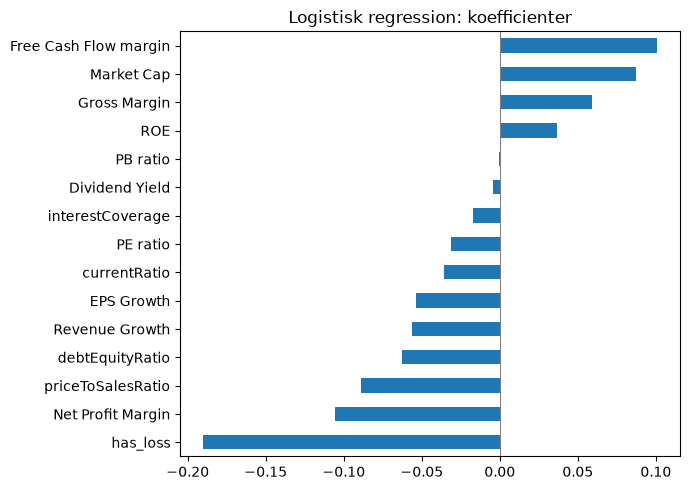

PE ratio                        -0.031
PB ratio                        -0.001
priceToSalesRatio               -0.089
ROE                              0.037
debtEquityRatio                 -0.063
currentRatio                    -0.035
Net Profit Margin               -0.106
Gross Margin                     0.059
Free Cash Flow margin            0.101
Revenue Growth                  -0.056
EPS Growth                      -0.054
Dividend Yield                  -0.004
interestCoverage                -0.017
Market Cap                       0.087
has_loss                        -0.190
Sector_Basic Materials           0.089
Sector_Communication Services   -0.056
Sector_Consumer Cyclical        -0.157
Sector_Consumer Defensive       -0.147
Sector_Energy                   -0.589
Sector_Financial Services        0.389
Sector_Healthcare               -0.098
Sector_Industrials               0.044
Sector_Real Estate              -0.012
Sector_Technology                0.175
Sector_Utilities         

In [16]:
model_coefs = lr_model.named_steps["model"].coef_[0]
sector_names = lr_model.named_steps["prep"].named_transformers_["sector"].get_feature_names_out()

coefs = pd.Series(model_coefs, index=FEATURES_FINAL + list(sector_names))
key_ratios = coefs[FEATURES_FINAL].sort_values()

key_ratios.plot(kind="barh", figsize=(7, 5), title="Logistisk regression: koefficienter")
plt.axvline(0, color="grey", linewidth=0.8)
plt.tight_layout()
plt.show()

coefs.round(3)

Förlust (`has_loss`, −0,19) är den starkaste negativa signalen. Hög
kassaflödesmarginal (+0,10) och högt börsvärde (+0,09) är de starkaste positiva.
Sektor väger dock tyngre än alla nyckeltal: Energy (−0,59) och Financial Services
(+0,39).

Enskilda koefficienter ska tolkas försiktigt. Flera nyckeltal hänger ihop, till
exempel vinstmarginal, förlust och kassaflödesmarginal. Därför kan ett nyckeltal
få oväntat tecken, som Net Profit Margin (−0,11).

In [17]:
ranked = test.assign(proba=proba).sort_values("proba", ascending=False)
show = ["Ticker", "Sector", "proba", "next_year_return"]

print("Modellens topp 10 för 2018:")
display(ranked.head(10)[show].round(2))
print("Modellens botten 10 för 2018:")
display(ranked.tail(10)[show].round(2))

Modellens topp 10 för 2018:


,Ticker,Sector,proba,next_year_return
78,MSCI,Financial Services,0.70,77.78
975,RY,Financial Services,0.70,20.24
16,WFC,Financial Services,0.70,19.22
107,ITUB,Financial Services,0.69,-0.42
5,BAC,Financial Services,0.69,44.32
122,USB,Financial Services,0.69,31.75
97,SCHW,Financial Services,0.69,16.24
308,MA,Financial Services,0.69,58.24
28,BBD,Financial Services,0.69,7.30
410,PNC,Financial Services,0.69,38.65


Modellens botten 10 för 2018:


,Ticker,Sector,proba,next_year_return
3780,ENSV,Energy,0.21,-55.71
3854,HUSA,Energy,0.20,-25.00
3820,GBR,Energy,0.20,-17.45
2955,MOTS,Healthcare,0.20,-31.64
2740,IO,Energy,0.19,50.43
2636,LLEX,Energy,0.19,-74.15
4039,SAEX,Energy,0.19,54.31
1785,ZIOP,Healthcare,0.18,113.57
3700,CCUR,Technology,0.17,26.09
3797,FAT,Consumer Cyclical,0.17,-11.05


Alla tio i topplistan är banker och finansbolag. Sju av dem slog medianen
(17,8 %), och nio av tio steg. Bottenlistan består mest av små energibolag.
Sex av dem gick sämre än medianen, men flera steg kraftigt.

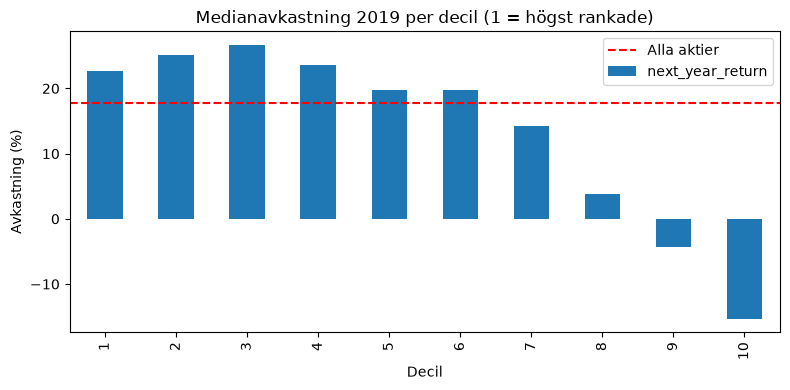

Decil
1     22.7
2     25.1
3     26.7
4     23.6
5     19.7
6     19.8
7     14.2
8      3.8
9     -4.3
10   -15.3
Name: next_year_return, dtype: float64

In [18]:
ranked["Decil"] = pd.qcut(ranked["proba"].rank(method="first", ascending=False),
                          10, labels=range(1, 11))
deciles = ranked.groupby("Decil", observed=True)["next_year_return"].median()

deciles.plot(kind="bar", figsize=(8, 4),
             title="Medianavkastning 2019 per decil (1 = högst rankade)")
plt.axhline(test["next_year_return"].median(), color="red", linestyle="--",
            label="Alla aktier")
plt.ylabel("Avkastning (%)")
plt.legend()
plt.tight_layout()
plt.show()

deciles.round(1)

De fyra högst rankade decilerna fick 23–27 % i medianavkastning, mot 17,8 % för
alla aktier. De tre lägsta fick 3,8 %, −4,3 % och −15,3 %. Modellen är alltså
bäst på att peka ut aktier att undvika. Skillnaden mellan de bästa decilerna är
liten.

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

sector_only = make_pipeline(OneHotEncoder(handle_unknown="ignore"),
                            LogisticRegression(max_iter=2000))
sector_only.fit(train[["Sector"]], train["above_median"])
sector_proba = sector_only.predict_proba(test[["Sector"]])[:, 1]

def auc_within_sector(df, proba):
    """Snitt av ROC-AUC räknad inom varje sektor, viktad efter antal bolag."""
    df = df.assign(proba=proba)
    aucs = df.groupby("Sector").apply(
        lambda g: pd.Series({"auc": roc_auc_score(g["above_median"], g["proba"]),
                             "n": len(g)}),
        include_groups=False,
    )
    return round(np.average(aucs["auc"], weights=aucs["n"]), 3)

pd.DataFrame({
    "ROC-AUC totalt": [
        round(roc_auc_score(test["above_median"], sector_proba), 3),
        round(roc_auc_score(test["above_median"], proba), 3),
    ],
    "ROC-AUC inom sektor": [
        auc_within_sector(test, sector_proba),
        auc_within_sector(test, proba),
    ],
}, index=["Bara sektor", "Vald modell (nyckeltal + sektor)"])

,ROC-AUC totalt,ROC-AUC inom sektor
Bara sektor,0.576,0.50
Vald modell (nyckeltal + sektor),0.630,0.61


Sektor ensam ger ROC-AUC 0,576, så en del av modellens förmåga kommer från att
välja rätt sektor. Inom varje sektor når modellen ändå 0,61. Nyckeltalen hjälper
alltså också till att skilja bra aktier från dåliga inom samma sektor.

Sektoreffekten är en risk. Modellen har lärt sig att energibolag går dåligt,
troligen från oljeprisfallet 2015. Om oljepriset stiger kan den slutsatsen bli fel.

## 5. Slutsatser

**Vad resultaten stödjer**
- Nyckeltal ger en svag men stabil signal: ROC-AUC 0,63 och cirka 60 % rätt
  på två år som modellen inte tränats på.
- En mer avancerad modell gav inte ett säkert bättre resultat. Gradient boosting
  var marginellt bättre båda åren, men inom osäkerheten.
- Hur datan förbehandlas betydde mer än vilken modell som användes.
- En enkel regel som "köp billiga aktier" (lågt P/B) fungerade inte under perioden.
- Modellen är mest användbar för att sålla bort aktier. De lägst rankade
  aktierna gick klart sämre än övriga.

**Vad resultaten inte stödjer**
- Att modellen är en lönsam investeringsstrategi. Vi har inte räknat med
  utdelningar, avgifter, skatt eller risk.
- Att resultaten gäller andra marknader eller andra tidsperioder.

**Begränsningar**
- Bara fem års data och två utvärderingsår.
- Överlevnadsbias: bolag som försvunnit kan saknas.
- Datan kommer från en enda källa och innehåller fel, till exempel orimliga avkastningar.
- Avkastningen mäter bara kursförändring, utan utdelningar.
- Modellen förlitar sig delvis på sektor, vilket gör den känslig för förändringar
  i marknaden.
- Teståret 2018 hade körts en gång tidigare i ett individuellt experiment.

**När lösningen inte bör användas**
- Som enda underlag för att köpa eller sälja en aktie.
- På andra marknader än den amerikanska utan ny utvärdering.